## H1 - Session completion rate

**Project hypothesis:** The redesigned website (Test) increases the session completion rate by at least **5 percentage points** compared with the original website (Control).

We use a one-sided test to assess whether the difference in completion rates (Test minus Control) falls short of that target.

- **Null hypothesis (H₀):** The difference is **at least 5 percentage points**.
- **Alternative hypothesis (Hₐ):** The difference is **less than 5 percentage points**.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import norm


sessions = pd.read_csv("../data/clean/sessions_data_master.csv")


In [2]:
# Identify sessions that count as completed
sessions["considered_completed"] = (
    (sessions["starts_at_start"] == True) &
    (sessions["last_step"] == "confirm") &
    (sessions["total_time_seconds"] <= 360)
)

sessions.head(5)



,client_id,visit_id,step_count,last_step,variation,completed,journey_status,out_of_order_count,step_backs_count,repeats_count,...,total_time_seconds,effective_time_seconds,starts_count,multiple_starts,confirms_count,multiple_confirms,first_start_time,first_confirm_time,completion_time_seconds,considered_completed
0,555,637149525_38041617439_716659,5,confirm,Test,True,Completed,0,0,0,...,158.0,158.0,1,False,1,False,2017-04-15 12:57:56,2017-04-15 13:00:34,158.0,True
1,647,40369564_40101682850_311847,5,confirm,Test,True,Completed,0,0,0,...,377.0,377.0,1,False,1,False,2017-04-12 15:41:28,2017-04-12 15:47:45,377.0,False
2,934,7076463_57954418406_971348,4,start,Test,False,Incomplete,3,0,3,...,142.0,0.0,4,True,0,False,2017-04-18 02:36:30,NaN,NaN,False
3,1028,557292053_87239438319_391157,9,step_1,Control,False,Incomplete,4,2,2,...,538.0,335.0,1,False,0,False,2017-04-08 18:51:28,NaN,NaN,False
4,1104,543158812_46395476577_767725,1,start,Control,False,Incomplete,0,0,0,...,0.0,0.0,1,False,0,False,2017-06-12 07:49:18,NaN,NaN,False


In [3]:
# Calculate the completion rate for each user group

session_completion_rate = (
    sessions.groupby("variation")["considered_completed"].mean() * 100
).round(2)

display(session_completion_rate)

variation
Control    28.72
Test       31.67
Name: considered_completed, dtype: float64

/var/folders/2v/9gm0hrts6d9bnr138z0178tc0000gn/T/ipykernel_70181/2406049104.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


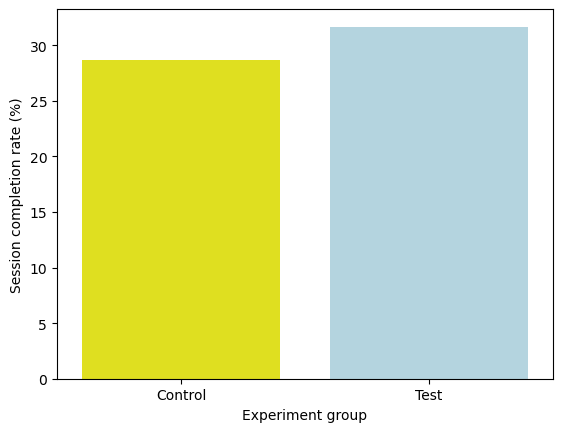

In [26]:
# Session completion rates
completion_rates = session_completion_rate[["Control", "Test"]]

ax = sns.barplot(
    x=completion_rates.index,
    y=completion_rates.values,
    palette=["yellow", "lightblue"],
)
ax.set_xlabel("Experiment group")
ax.set_ylabel("Session completion rate (%)")

plt.savefig("../figures/h1_session_completion.png", dpi=300, bbox_inches="tight")

plt.show()

In [5]:
difference_pp = session_completion_rate["Test"] - session_completion_rate["Control"]

print(f"Test session completion rate: {session_completion_rate['Test']:.2f}%")
print(f"Control session completion rate: {session_completion_rate['Control']:.2f}%")
print(f"Observed difference: the Test user group rate is {difference_pp:+.2f} percentage points higher than the Control rate.")

Test session completion rate: 31.67%
Control session completion rate: 28.72%
Observed difference: the Test user group rate is +2.95 percentage points higher than the Control rate.


In [6]:

# Count completed and total sessions for each client
client_counts = (
    sessions.groupby(["variation", "client_id"])["considered_completed"]
    .agg(completed_sessions="sum", total_sessions="size")
)

rates = {}
variances = {}

for group in ["Test", "Control"]:
    clients = client_counts.loc[group]

    # Calculate the completion rate across all sessions in this group
    total_sessions = clients["total_sessions"].sum()
    rate = clients["completed_sessions"].sum() / total_sessions
    rates[group] = rate

    # Estimate uncertainty while keeping each client's sessions together
    residuals = clients["completed_sessions"] - rate * clients["total_sessions"]
    n_clients = len(clients)
    variances[group] = (
        n_clients / (n_clients - 1) * (residuals**2).sum() / total_sessions**2
    )

# Test whether the completion lift falls short of 5 percentage points
lift = rates["Test"] - rates["Control"]
standard_error = (variances["Test"] + variances["Control"]) ** 0.5
z_stat = (lift - 0.05) / standard_error
p_value = norm.cdf(z_stat)

print(f"Observed completion lift (Test minus Control): {lift * 100:+.2f} percentage points")
print(f"One-sided p-value for a lift below 5 percentage points: {p_value:.4g}")

Observed completion lift (Test minus Control): +2.95 percentage points
One-sided p-value for a lift below 5 percentage points: 8.527e-09


In [7]:
# Compare Effective Time in seconds between Test and Control
display(
    sessions.groupby("variation")["effective_time_seconds"]
    .describe()
    .round(2)
)

,count,mean,std,min,25%,50%,75%,max
variation,,,,,,,,
Control,32243.0,171.18,219.77,0.0,0.0,114.0,245.0,3312.0
Test,37204.0,163.27,218.95,0.0,7.0,112.0,219.0,4548.0


In [8]:
# Analyze whether some steps created more friction than others
# Check sessions whose total duration was more than 300 seconds & calculate the percentage in each group

sessions["over_300_sec"] = sessions["total_time_seconds"] > 300

slow_session_rate = (
    sessions.groupby("variation")["over_300_sec"].mean() * 100
).round(2)

display(slow_session_rate)

variation
Control    28.89
Test       30.13
Name: over_300_sec, dtype: float64

In [9]:
# Check sessions whose first recorded step was not start & calculate the percentage for each group

sessions["missing_start"] = sessions["starts_at_start"] == False

missing_start_rate = (
    sessions.groupby("variation")["missing_start"].mean() * 100
).round(2)

display(missing_start_rate)

variation
Control     4.14
Test       11.15
Name: missing_start, dtype: float64

In [10]:
# Check sessions with at least one skip, repeat or backward move & calculate percentage for each group
sessions["out_of_order"] = sessions["out_of_order_count"] > 0


out_of_order_rate = (
    sessions.groupby("variation")["out_of_order"].mean() * 100
).round(2)

display(out_of_order_rate)

variation
Control    37.45
Test       45.01
Name: out_of_order, dtype: float64

In [11]:
sessions.head()

,client_id,visit_id,step_count,last_step,variation,completed,journey_status,out_of_order_count,step_backs_count,repeats_count,...,multiple_starts,confirms_count,multiple_confirms,first_start_time,first_confirm_time,completion_time_seconds,considered_completed,over_300_sec,missing_start,out_of_order
0,555,637149525_38041617439_716659,5,confirm,Test,True,Completed,0,0,0,...,False,1,False,2017-04-15 12:57:56,2017-04-15 13:00:34,158.0,True,False,False,False
1,647,40369564_40101682850_311847,5,confirm,Test,True,Completed,0,0,0,...,False,1,False,2017-04-12 15:41:28,2017-04-12 15:47:45,377.0,False,True,False,False
2,934,7076463_57954418406_971348,4,start,Test,False,Incomplete,3,0,3,...,True,0,False,2017-04-18 02:36:30,NaN,NaN,False,False,False,True
3,1028,557292053_87239438319_391157,9,step_1,Control,False,Incomplete,4,2,2,...,False,0,False,2017-04-08 18:51:28,NaN,NaN,False,True,False,True
4,1104,543158812_46395476577_767725,1,start,Control,False,Incomplete,0,0,0,...,False,0,False,2017-06-12 07:49:18,NaN,NaN,False,False,False,False


In [12]:
# Mark whether each session had a skip, repeat, or backward move
navigation_friction = sessions[
    ["skips_count", "repeats_count", "step_backs_count"]
] > 0

# Calculate the percentage of sessions with each behavior by experiment group
navigation_friction_rates = (
    navigation_friction.groupby(sessions["variation"]).mean() * 100
).round(2)

display(navigation_friction_rates)

,skips_count,repeats_count,step_backs_count
variation,,,
Control,1.14,24.81,20.23
Test,2.08,29.17,26.80


In [13]:
# Mark a session if it took over 300 seconds, started at a different recorded step, or included a skip, repeat or backward move
high_friction = (
    (sessions["total_time_seconds"] > 300)
    | (sessions["starts_at_start"] == False)
    | (sessions["out_of_order_count"] > 0)
)

# Calculate the percentage of high-friction sessions in each group
high_friction_rate = high_friction.groupby(sessions["variation"]).mean() * 100

display(high_friction_rate[["Control", "Test"]].round(2))

sessions["high_friction"] = high_friction

variation
Control    50.67
Test       60.15
dtype: float64

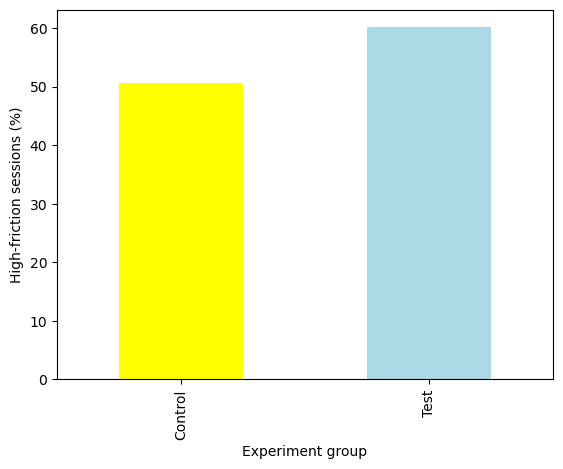

In [25]:
# Compare the percentage of high-friction sessions in Control and Test
# Compare high-friction rates in Control and Test
ax = high_friction_rate[["Control", "Test"]].plot.bar(
    color=["yellow", "lightblue"]
)
ax.set_xlabel("Experiment group")
ax.set_ylabel("High-friction sessions (%)")

plt.savefig("../figures/h1_high_friction_rate.png", dpi=300, bbox_inches="tight")
plt.show()

In [15]:
# This code was already applied in the master_session_data notebook, but it's required for this analysis
# Load the event data, sort events within each visit, and map steps to numbers
web_data = pd.read_csv("../data/clean/cleaned_web_data.csv")
web_data["date_time"] = pd.to_datetime(web_data["date_time"])
web_data = web_data.sort_values(["client_id", "visit_id", "date_time"])

step_order = {"start": 0, "step_1": 1, "step_2": 2, "step_3": 3, "confirm": 4}
web_data["step_num"] = web_data["process_step"].map(step_order)


In [16]:
# Compare each event with the next event so we flag the step where the move began
next_step_num = web_data.groupby(["client_id", "visit_id"])["step_num"].shift(-1)
step_change = next_step_num - web_data["step_num"]

web_data["friction_from_step"] = step_change.notna() & (step_change != 1)

In [17]:
# Display whether each visit had any navigation friction at any step
friction_by_session_step = (
    web_data.groupby(["client_id", "visit_id", "variation", "process_step"])[
        "friction_from_step"
    ]
    .any()
    .reset_index()
)

display(friction_by_session_step.head(10))


,client_id,visit_id,variation,process_step,friction_from_step
0,555,637149525_38041617439_716659,Test,confirm,False
1,555,637149525_38041617439_716659,Test,start,False
2,555,637149525_38041617439_716659,Test,step_1,False
3,555,637149525_38041617439_716659,Test,step_2,False
4,555,637149525_38041617439_716659,Test,step_3,False
5,647,40369564_40101682850_311847,Test,confirm,False
6,647,40369564_40101682850_311847,Test,start,False
7,647,40369564_40101682850_311847,Test,step_1,False
8,647,40369564_40101682850_311847,Test,step_2,False
9,647,40369564_40101682850_311847,Test,step_3,False


In [18]:
# Check from the visits that reached this step, what percentage skipped, repeated, or moved backward from it
friction_by_step = (
    friction_by_session_step.pivot_table(
        index="process_step",
        columns="variation",
        values="friction_from_step",
        aggfunc="mean",
    ).reindex(
        index=["start", "step_1", "step_2", "step_3", "confirm"],
        columns=["Control", "Test"],
    ) * 100
)

display(friction_by_step[["Control", "Test"]].round(2))

variation,Control,Test
process_step,,
start,18.57,21.75
step_1,12.08,22.00
step_2,12.01,16.20
step_3,19.94,18.33
confirm,8.86,13.97


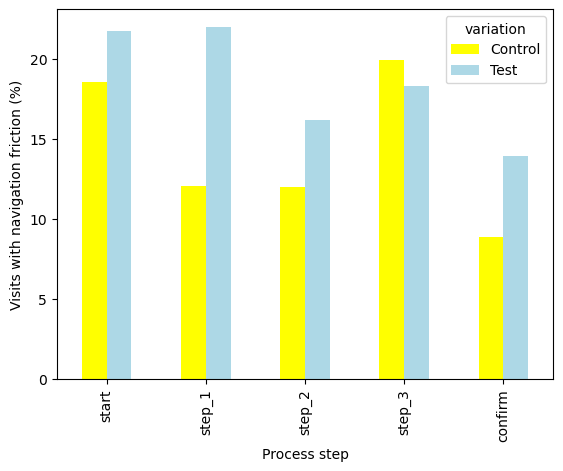

In [19]:
# Navigation friction by step
ax = friction_by_step[["Control", "Test"]].plot.bar(
    color=["yellow", "lightblue"]
)
ax.set_xlabel("Process step")
ax.set_ylabel("Visits with navigation friction (%)")

plt.savefig("../figures/h1_navigation_friction_by_step.png", dpi=300, bbox_inches="tight")
plt.show()

## Conclusions

### Session completion fell short of the 5-percentage-point target

A session counted as **completed** if it began at `start`, ended at `confirm`, and lasted **360 seconds or less**. We chose 360 seconds because it was the **75th percentile of completion times**. For each group, the completion rate was the number of sessions that met all three criteria divided by the total number of recorded sessions.

- **H₀:** The Test completion rate is at least 5 percentage points higher than the Control rate.
- **Hₐ:** The difference in completion rates (Test minus Control) is below 5 percentage points.

The completion rate was **31.67% in Test** and **28.72% in Control**, an observed difference of **+2.95 percentage points**. The one-sided test accounted for multiple sessions from the same client and gave **p = 8.527 × 10⁻⁹**. At the 5% significance level, we rejected H₀. The results support a completion-rate improvement below the 5-percentage-point target.

### Effective Time was slightly lower in Test

Effective Time adds together the seconds between events where the client moved forward by exactly one step, such as `step_1 → step_2`. We exclude intervals ending in a repeat, skip, or backward move. If the client goes backward and then moves forward again, that new forward interval counts too.

The median Effective Time was **112 seconds in Test** and **114 seconds in Control**. The mean was **163.27 seconds in Test** and **171.18 seconds in Control**, a difference of **7.91 seconds**.

These results cover all sessions, including those that ended early. A session can have a low Effective Time because the client progressed quickly or because they stopped after only a few steps. The intervals can also include pauses away from the screen. We therefore interpret these results alongside completion rates and treat the differences as descriptive.

### High-friction journeys were more common in Test

A session counted as **high-friction** if it lasted **more than 300 seconds**, its first recorded event was a step other than `start`, or it included a skip, repeat, or backward move. The 300-second threshold was based on the **mean session duration**. Each session counted once, even if it met several criteria. A session that began at `start`, ended at `confirm`, and took 330 seconds qualified as both completed and high-friction.

The observed high-friction rate was **60.15% in Test** and **50.67% in Control**, a difference of **+9.48 percentage points**. Backward moves showed the largest gap (**+6.57 percentage points**), followed by repeats (**+4.36**) and skips (**+0.94**). These comparisons are descriptive.

### `step_1` showed the largest increase in navigation friction

For each step, we measured the share of visits that reached it and then skipped, repeated, or moved backward from it at least once. Each visit counted once per step. The `confirm` row captures navigation after a recorded confirmation within the same visit.

The largest gap was at **`step_1`**, where **22.00%** of Test visits had navigation friction compared with **12.08%** of Control visits, a difference of **+9.92 percentage points**. At `confirm`, the rate was **13.97% in Test** and **8.86% in Control**. **`step_3`** was the only step with a lower rate in Test (**18.33% vs. 19.94%**).

In [28]:
import subprocess

subprocess.run(["open", "../figures"])

CompletedProcess(args=['open', '../figures'], returncode=0)